## Motif-8 mutants at nhomie and homie

Includes merged and per-replicate information.

In [1]:
import coolbox
from coolbox.api import *

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from generic_plotting_functions import *

import pandas as pd
import os
import numpy as np

from load_modisco import *
import json
from domino.utils.tools import seq_from_df
from domino.data.domino_data import preprocess_data, process_bed_file_df

import pysam

In [2]:
import glob
def get_mut_file(mut, replicates=False):
    files = glob.glob(f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/{mut}/*.mcool')
    if not replicates:
        return [f for f in files if 'merged' in f]
    return [f for f in files if 'merged' not in f]

In [3]:
muts = ('old_homie', 'nhomie', 'homie_m8_mut', 'nhomie_m8_mut', 'homie', 'final_homie')
mut2insbed = dict()
ins_bed_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/'
mcool_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/"

for m in muts:
    mut2insbed[m] = dict()
    for ws in [1,2,4,8,16,32,48]:
        if m != 'old_homie':
            mut2insbed[m][str(ws)] = os.path.join(ins_bed_dir, f'{m}.resolution=200bp.insulation_{ws}kb.bed')
        else:
            mut2insbed[m][str(ws)] = os.path.join(ins_bed_dir, m, f'{m.replace("old_", "")}.resolution=200bp.insulation_{ws}kb.bed')

In [4]:
HEBE_chrom, HEBE_start, HEBE_end = 'chr2R', 9837401, 9837600

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.4, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3, 
    grid=False,
)

In [6]:
def get_replicate_insulation(mut, ws):
    if mut == "final_homie":
        files = glob.glob(f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/{mut}/*{ws}kb.bed')
        return [f for f in files if 'CDEF_Z5_1' not in f and 'CDEFZ5_all' not in f]
    return glob.glob(f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/{mut}/*{ws}kb.bed')

In [7]:
mut2color = {'final_homie': 'brown', 'nhomie': 'red', 'homie_m8_mut': 'purple', 'nhomie_m8_mut': 'green'}
ws2demean_ins_scores = dict()
demeaned_ins_scores = dict()
demeaned_y_tracks = dict()

ws = 16
RADIUS=50
for mut in ['final_homie', 'nhomie', 'homie_m8_mut', 'nhomie_m8_mut']:
    
    
    # compute raw insulation score
    for i, ins_bed_path in enumerate(get_replicate_insulation(mut, ws)):
        # ins_bed_path = ins_dict[str(ws)]
        ins_score1 = process_bed_file_df(ins_bed_path, target_col='ins_score')
    
        chrom, start, end = HEBE_chrom, HEBE_start, HEBE_end
        
        # get insulation around boundary of interest
        tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
        locus_df = ins_score1.iloc[tmp.index.item() - RADIUS:tmp.index.item() + RADIUS+1]
        # print(locus_df.iloc[RADIUS])
        
        ins_score_context_bin_width=10
        idxs_pos = np.array([np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1) for i in locus_df.index])
        y_pos = np.array([np.array(ins_score1['ins_score'][idx_arr]) for idx_arr in idxs_pos])  # slide demean windows across sequence (210, 21)
        demeaned_y1_pos = y_pos - np.mean(y_pos, axis=1)[:, np.newaxis] # demean for middle bins and all other bins (210, 1)
        middle_points1_pos = demeaned_y1_pos[:, ins_score_context_bin_width] # just get demeaned value of interest (210, 1)
        x, y = np.arange(-len(middle_points1_pos)//2, len(middle_points1_pos)//2) + 1, middle_points1_pos
                
        # If the middle bin is undefined, do not append 
        if np.isnan(y.tolist()[RADIUS]):
            continue

        # store middle bin and track
        if mut not in demeaned_ins_scores:
            demeaned_ins_scores[mut] = [y.tolist()[RADIUS]]
            demeaned_y_tracks[mut] = [y.tolist()]
        else:
            demeaned_ins_scores[mut].append(y.tolist()[RADIUS])
            demeaned_y_tracks[mut].append(y.tolist())
            

In [8]:
# take the mean track of all replicates
final_y_tracks = dict()
for mut, arr in demeaned_y_tracks.items():
    new_arr = arr.copy()
    print(mut, len(new_arr))
    final_y_tracks[mut] = np.nanmean(np.array(new_arr), axis=0)

final_homie 4
nhomie 2
homie_m8_mut 3
nhomie_m8_mut 3


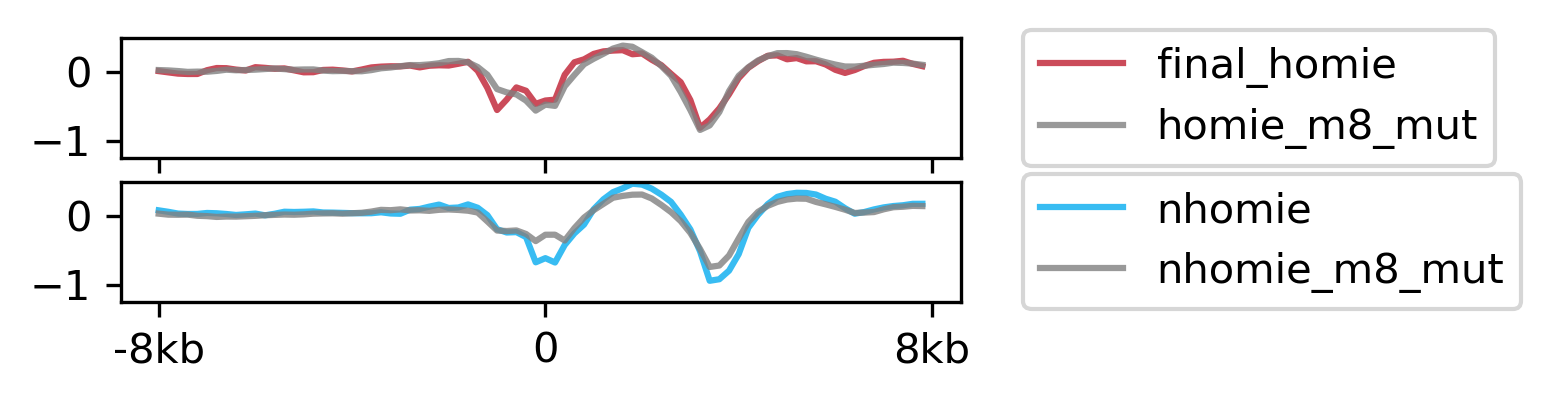

In [10]:
fig, axs = init_subplots_exact(2, 2, dpi=300, y_ratios=[0.1]*2, x_ratios=[0.7])

axs[0].plot(final_y_tracks['final_homie'][10:90], label='final_homie', c="#bf1e31", lw=1.5, alpha=0.8)
axs[0].plot(final_y_tracks['homie_m8_mut'][10:90], label='homie_m8_mut', c="#808080", lw=1.5, alpha=0.8)

axs[1].plot(final_y_tracks['nhomie'][10:90], label='nhomie', c="#06acef", lw=1.5, alpha=0.8)
axs[1].plot(final_y_tracks['nhomie_m8_mut'][10:90], label='nhomie_m8_mut', c="#808080", lw=1.5, alpha=0.8)

for ax in axs:
    ax.legend(bbox_to_anchor=(1.05, 0.5), loc='center left')
    ax.set_ylim(-1.25, 0.5)
    ax.set_xticks([0, 40, 80])
axs[1].set_xticklabels(['-8kb', '0', '8kb'])
plt.show()
# fig.savefig("plots/nhomie_homie_m8_insulation_tracks.pdf", format="pdf", dpi=300, bbox_inches='tight')

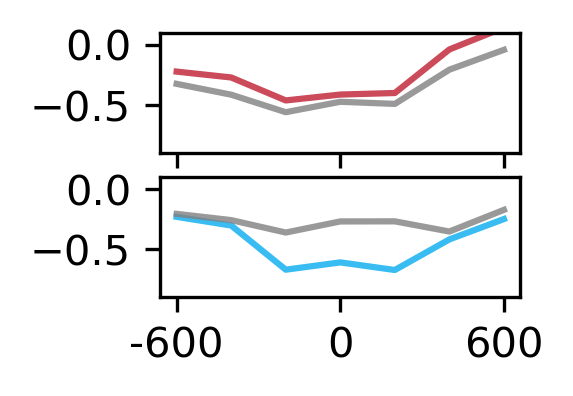

In [11]:
fig, axs = init_subplots_exact(2, 2, dpi=300, y_ratios=[0.1]*2, x_ratios=[0.3])

axs[0].plot(final_y_tracks['final_homie'][47:54], label='final_homie', c="#bf1e31", lw=1.5, alpha=0.8)
axs[0].plot(final_y_tracks['homie_m8_mut'][47:54], label='homie_m8_mut', c="#808080", lw=1.5, alpha=0.8)

axs[1].plot(final_y_tracks['nhomie'][47:54], label='nhomie', c="#06acef", lw=1.5, alpha=0.8)
axs[1].plot(final_y_tracks['nhomie_m8_mut'][47:54], label='nhomie_m8_mut', c="#808080", lw=1.5, alpha=0.8)

for ax in axs:
    # ax.legend(bbox_to_anchor=(1.05, 0.5), loc='center left')
    ax.set_ylim(-0.9, 0.1)
    ax.set_xticks([0, 3, 6])
    axs[1].set_xticklabels([-600, 0, 600])
plt.show()
# fig.savefig("plots/nhomie_homie_m8_insulation_tracks_zoomed.pdf", format="pdf", dpi=300, bbox_inches='tight')

# Insulation at the exact hebe insertion site across replicates

In [12]:
# create dataframe with condition, time (before or after deletion) and insulation values
rows = []
for key, values in demeaned_ins_scores.items():
    time = 'M8' if 'mut' not in key else 'ΔM8'
    k = key.replace('_m8_mut', '').replace('final_', '')
    for v in values:
        rows.append({
            "condition": k,
            "time": time,
            "value": v
        })
df = pd.DataFrame(rows)
df['group'] = df.condition + df.time

In [13]:
from scipy.stats import mannwhitneyu
from scipy.stats import ttest_ind

pvals = {}
for cond in ['homie', 'nhomie']:
    before = df.query("condition == @cond and time == 'M8'")["value"].tolist()
    after  = df.query("condition == @cond and time == 'ΔM8'")["value"].tolist()
    _, p = ttest_ind(before, after, alternative="less")
    pvals[cond] = p

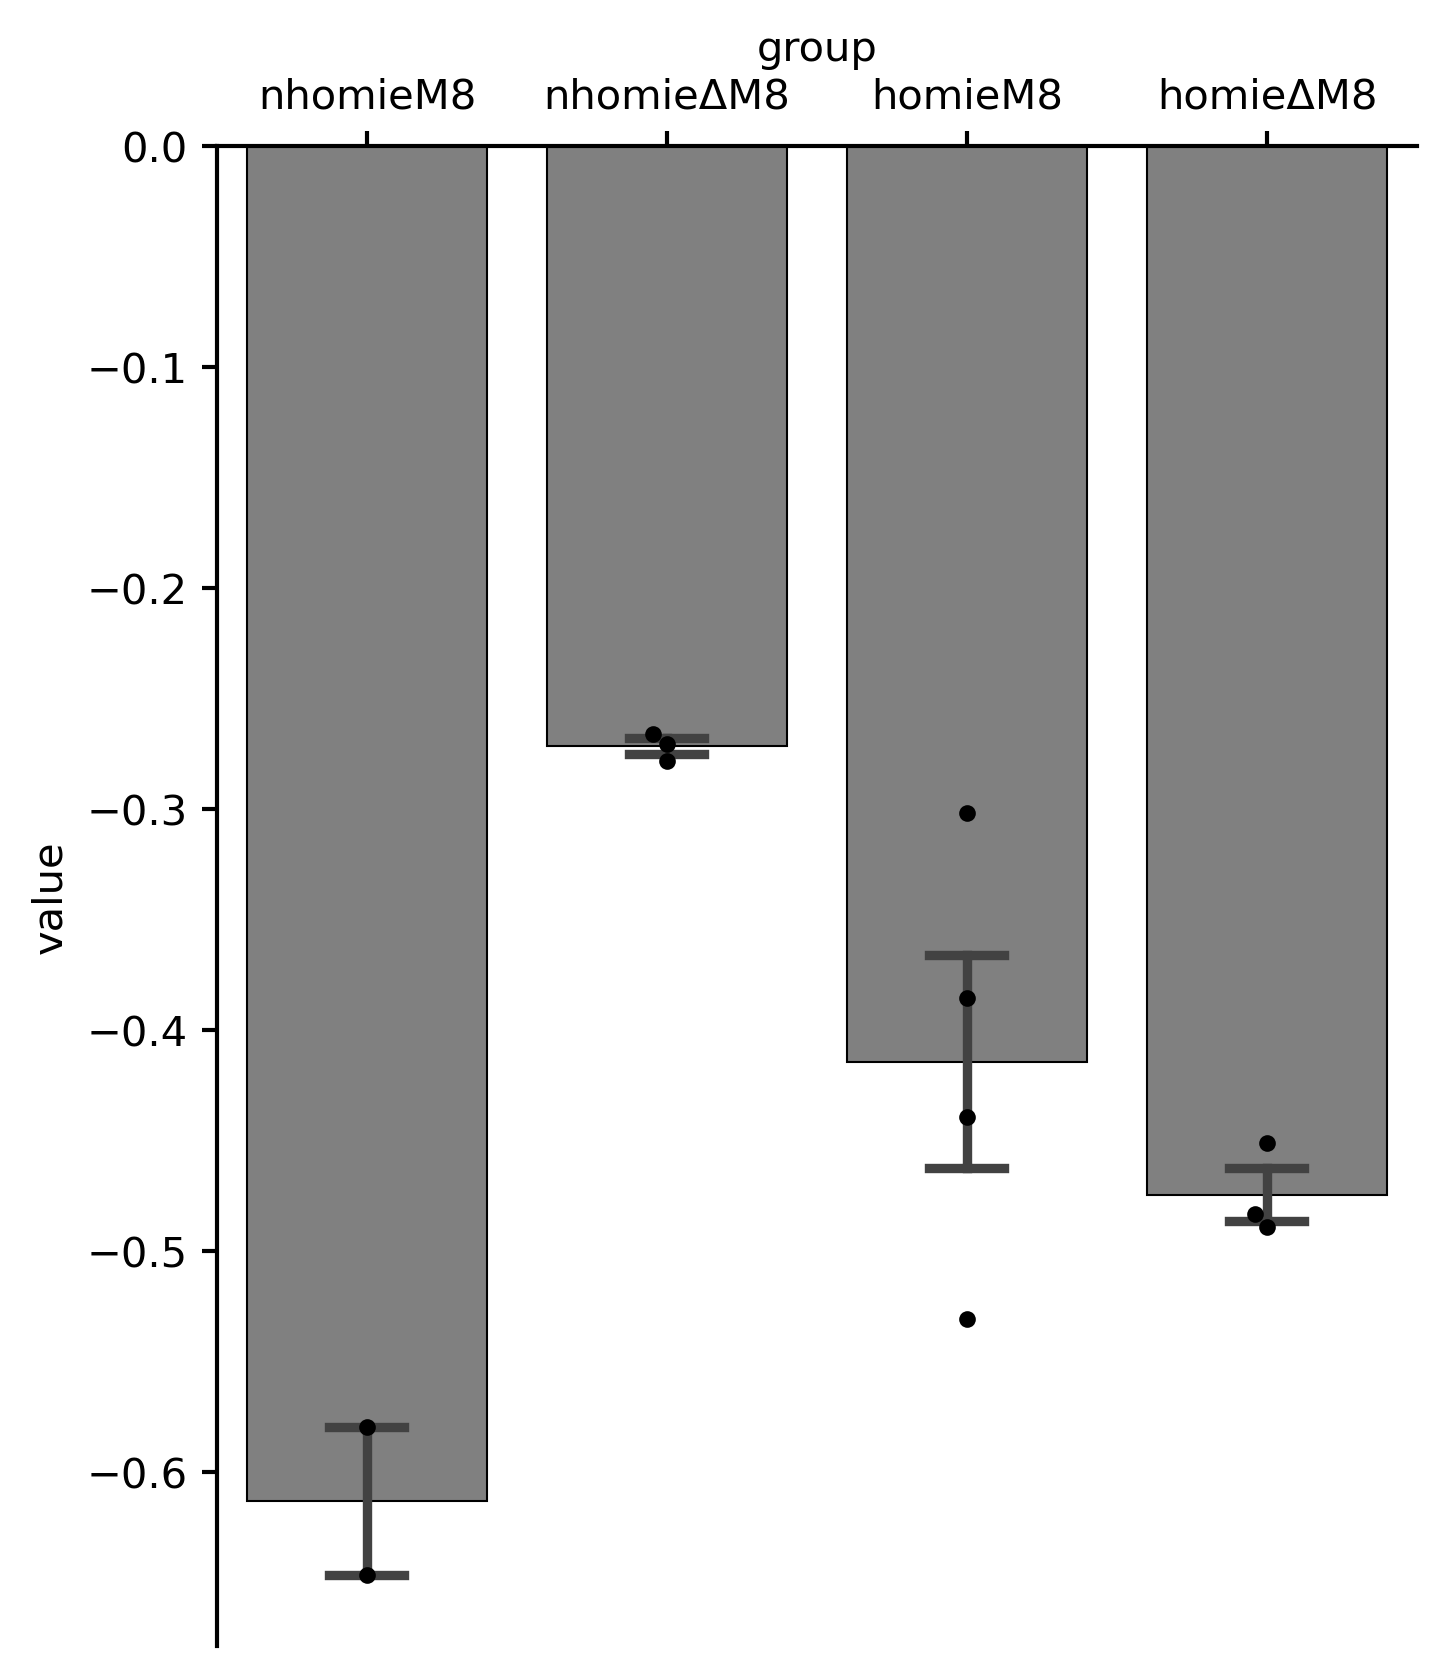

In [14]:
import seaborn as sns
fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[1.25])

colors = {
    "nhomieM8": "#808080",  # gray
    "nhomieΔM8":  "#808080",  # gray
    "homieM8": "#808080",  # gray
    "homieΔM8":  "#808080"  # gray
}

order = ["nhomieM8", "nhomieΔM8", "homieM8", "homieΔM8"]
sns.barplot(data=df, x="group", y="value", errorbar="se", capsize=0.25, order=order, palette=colors,
             edgecolor="black",
            linewidth=0.5)
sns.swarmplot(data=df, x="group", y="value",
              color="black", size=4, order=order)

for spine in ax.spines.values():
    spine.set_linewidth(1)

ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)

ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

ax.tick_params(width=1)

plt.show()
# fig.savefig("plots/motif8_mutant_insulation_barplot.pdf", format="pdf", dpi=300, bbox_inches='tight')

